 # Customer Churn Prediction — Exploratory Data Analysis

**Objective:** Understand which customers are likely to churn from property/telecom-style features.  
**Target variable:** `churn` (`Yes` / `No`)  
**Context:** Messy customer data loaded from CSV for practicing a full EDA workflow end to end (same step pattern as the house-price EDA session).

### How to use this notebook
Work top to bottom. Each numbered step has:
1. A short **why** (purpose of the step)
2. Code that performs the step (fill every `# TODO` cell)
3. Space for insights at the end

| Step | Focus |
|------|--------|
| 1–2 | Load / inspect |
| 3–5 | Missing values, duplicates, dtypes |
| 6–7 | Summaries & outliers |
| 8 | Binning (after outliers) |
| 9–11 | Uni / bi / multivariate visuals |
| 12 | Key findings (markdown) |

**Dataset file:** `customer_churn.csv` (same folder as this notebook).

**Required names for grading:** `df`, `raw_shape`, `missing_df`, `num_cols_with_na`, `cat_cols_with_na`, `df_before_outliers`, `outliers_iqr_mask`, `age_bin`, `corr_matrix`, `multi_corr`, `top_corr_with_churn`

# **Important**:Make sure you use the same variable name mentioned above

## 0. Imports

Import numpy, pandas, matplotlib, seaborn, and display helpers.

In [48]:
pip install numpy pandas matplotlib seaborn ipython

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [49]:
# TODO: Write your solution here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML, Markdown

## 1. Load Dataset

### Why this step
EDA starts with data on disk. Load `customer_churn.csv` so the rest of the notebook mirrors a real workflow: read a file, then clean and plot.

### What the code does
1. Reads the CSV with `pd.read_csv` into **`df`**.
2. Prints shape and column names, then shows the first few rows.

In [50]:
# TODO: Write your solution here.
df = pd.read_csv('customer_churn.csv')

In [51]:
df.shape

(518, 12)

In [52]:
df.columns

Index(['customer_id', 'age', 'tenure_months', 'monthly_charges',
       'total_charges', 'num_support_tickets', 'contract_type',
       'internet_service', 'payment_method', 'gender', 'partner', 'churn'],
      dtype='str')

In [53]:
df.head()

,customer_id,age,tenure_months,monthly_charges,total_charges,num_support_tickets,contract_type,internet_service,payment_method,gender,partner,churn
0,C10000,19.0,6,84.50,506.79,6,Month-to-month,Fiber optic,Credit card,Female,No,Yes
1,C10001,27.0,56,106.48,5951.56,4,Two year,No,Electronic check,Male,Yes,No
2,C10002,24.0,47,64.30,3449.02,0,One year,Fiber optic,Credit card,Female,No,No
3,C10003,NaN,32,43.28,1335.41,7,One year,Fiber optic,Credit card,Female,No,No
4,C10004,56.0,31,42.14,1266.18,3,One year,Fiber optic,Credit card,Female,No,No


## 2. Inspect the Data

### Why this step
Never clean or model blind. First look at samples and types so you know what each column is and whether missing values already appear.

### What the code does
- `head()` / `tail()`: first and last rows
- `dtypes`: int / float / object
- `info()`: non-null counts and memory

In [54]:
# TODO: Write your solution here.
df.head()

,customer_id,age,tenure_months,monthly_charges,total_charges,num_support_tickets,contract_type,internet_service,payment_method,gender,partner,churn
0,C10000,19.0,6,84.50,506.79,6,Month-to-month,Fiber optic,Credit card,Female,No,Yes
1,C10001,27.0,56,106.48,5951.56,4,Two year,No,Electronic check,Male,Yes,No
2,C10002,24.0,47,64.30,3449.02,0,One year,Fiber optic,Credit card,Female,No,No
3,C10003,NaN,32,43.28,1335.41,7,One year,Fiber optic,Credit card,Female,No,No
4,C10004,56.0,31,42.14,1266.18,3,One year,Fiber optic,Credit card,Female,No,No


In [55]:
df.tail()

,customer_id,age,tenure_months,monthly_charges,total_charges,num_support_tickets,contract_type,internet_service,payment_method,gender,partner,churn
513,C10084,79.0,45,NaN,1324.55,5,Month-to-month,DSL,Electronic check,Female,Yes,Yes
514,C10371,36.0,48,67.95,3486.47,2,Two year,DSL,Mailed check,Male,No,No
515,C10388,44.0,65,96.92,5779.48,6,Month-to-month,Fiber optic,Credit card,Male,Yes,No
516,C10495,52.0,30,67.93,1787.24,7,Month-to-month,DSL,Credit card,Female,Yes,Yes
517,C10030,46.0,32,22.43,765.80,4,One year,DSL,Bank transfer,Female,Yes,No


In [56]:
df.dtypes

customer_id                str
age                    float64
tenure_months            int64
monthly_charges        float64
total_charges          float64
num_support_tickets      int64
contract_type              str
internet_service           str
payment_method             str
gender                     str
partner                    str
churn                      str
dtype: object

In [57]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 518 entries, 0 to 517
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          518 non-null    str    
 1   age                  489 non-null    float64
 2   tenure_months        518 non-null    int64  
 3   monthly_charges      494 non-null    float64
 4   total_charges        498 non-null    float64
 5   num_support_tickets  518 non-null    int64  
 6   contract_type        502 non-null    str    
 7   internet_service     504 non-null    str    
 8   payment_method       518 non-null    str    
 9   gender               518 non-null    str    
 10  partner              518 non-null    str    
 11  churn                518 non-null    str    
dtypes: float64(3), int64(2), str(7)
memory usage: 48.7 KB


## 3. Handle Missing Values

### Why this step
Models and many aggregations fail or become biased when NaNs remain. Find gaps first, then choose a fill strategy that matches each column type.

### 3a. Count nulls
Create **`missing_df`** with columns `Missing` and `Percent`, filtered to columns that have nulls, sorted descending.

In [58]:
# TODO: Write your solution here.
# 3a. Count nulls
missing_df = pd.DataFrame({
    "Missing": df.isnull().sum(),
    "Percent": (df.isnull().mean() * 100).round(2)
})

missing_df = (
    missing_df[missing_df["Missing"] > 0]
    .sort_values("Missing", ascending=False)
)

display(missing_df)

,Missing,Percent
age,29,5.60
monthly_charges,24,4.63
total_charges,20,3.86
contract_type,16,3.09
internet_service,14,2.70


### 3b. Inspect numeric missing values (skew → mean vs median)

For skewed numerics prefer **median**; for roughly symmetric prefer **mean**.

Print **`num_cols_with_na`** and **`cat_cols_with_na`**.  
Plot a histogram for a skewed numeric column with nulls (e.g. `monthly_charges`) and print mean / median / mode.

Numeric columns with NaN:     ['age', 'monthly_charges', 'total_charges']
Categorical columns with NaN: ['contract_type', 'internet_service']


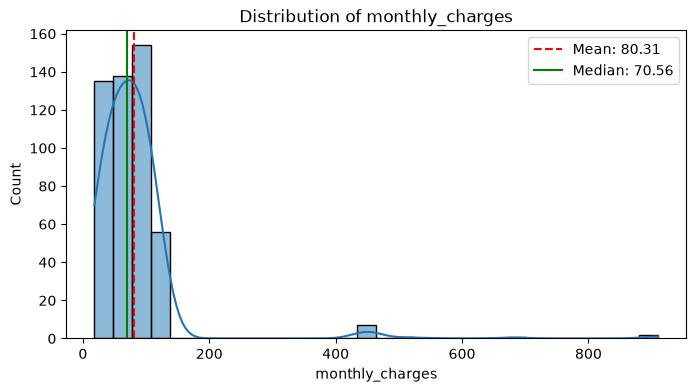

Mean:   80.31
Median: 70.56
Mode:   450.00
Skew:   6.42


In [59]:
# TODO: Write your solution here.
# 3b. Inspect numeric missing values (skew → mean vs median)

# Columns that still contain nulls, split by dtype
cols_with_na = missing_df.index.tolist()

num_cols_with_na = [c for c in cols_with_na if pd.api.types.is_numeric_dtype(df[c])]
cat_cols_with_na = [c for c in cols_with_na if not pd.api.types.is_numeric_dtype(df[c])]

print("Numeric columns with NaN:    ", num_cols_with_na)
print("Categorical columns with NaN:", cat_cols_with_na)

# Inspect one skewed numeric column with nulls
col = "monthly_charges"
if col in num_cols_with_na:
    data = df[col].dropna()

    plt.figure(figsize=(8, 4))
    sns.histplot(data, kde=True, bins=30)
    plt.axvline(data.mean(),   color="red",   linestyle="--", label=f"Mean: {data.mean():.2f}")
    plt.axvline(data.median(), color="green", linestyle="-",  label=f"Median: {data.median():.2f}")
    plt.title(f"Distribution of {col}")
    plt.legend()
    plt.show()

    print(f"Mean:   {data.mean():.2f}")
    print(f"Median: {data.median():.2f}")
    print(f"Mode:   {data.mode().iloc[0]:.2f}")
    print(f"Skew:   {data.skew():.2f}")
else:
    print(f"'{col}' has no missing values or is not numeric.")

### 3c. Inspect categorical missing values

For each categorical column with nulls, print the **mode** and **unique values**.

In [60]:
# TODO: Write your solution here.
# 3c. Inspect categorical missing values

for col in cat_cols_with_na:
    print(f"Column Name: {col}")
    print("Mode:", df[col].mode().iloc[0])
    print("Unique values:", df[col].dropna().unique())
    print()

Column Name: contract_type
Mode: Month-to-month
Unique values: <StringArray>
['Month-to-month', 'Two year', 'One year']
Length: 3, dtype: str

Column Name: internet_service
Mode: Fiber optic
Unique values: <StringArray>
['Fiber optic', 'No', 'DSL']
Length: 3, dtype: str



### 3d. Fill missing values

Fill in place on **`df`**:
- Numeric: **median** when `|skew| > 0.5`, else **mean**
- Categorical: **mode**
- Any leftover numeric NaNs: `ffill` then `bfill`
- Verify remaining missing count is **0**

In [61]:
# TODO: Write your solution here.
# 3d. Fill missing values (in place on df)

# Numeric: median if skewed, else mean
for col in num_cols_with_na:
    if abs(df[col].skew()) > 0.5:
        fill_value = df[col].median()
        strategy = "median"
    else:
        fill_value = df[col].mean()
        strategy = "mean"
    df[col] = df[col].fillna(fill_value)
    print(f"{col}: filled with {strategy} ({fill_value:.2f})")

# Categorical: mode
for col in cat_cols_with_na:
    mode_value = df[col].mode().iloc[0]
    df[col] = df[col].fillna(mode_value)
    print(f"{col}: filled with mode ({mode_value})")

# Any leftover numeric NaNs: forward fill, then backward fill
num_cols = df.select_dtypes(include="number").columns
df[num_cols] = df[num_cols].ffill().bfill()

# Verify
print("\nRemaining missing values:", df.isnull().sum().sum())

age: filled with mean (47.75)
monthly_charges: filled with median (70.56)
total_charges: filled with median (1981.05)
contract_type: filled with mode (Month-to-month)
internet_service: filled with mode (Fiber optic)

Remaining missing values: 0


## 4. Duplicate Records

### Why this step
Exact duplicate rows overweight the same customer in averages, correlations, and model training.

### What the code does
Count duplicates with `duplicated()`, then remove them with `drop_duplicates()` and reset the index.

In [62]:
# TODO: Write your solution here.
# 4. Duplicate Records

# Count exact duplicate rows
dup_count = df.duplicated().sum()
print(f"Duplicate rows before: {dup_count}")

# Remove them and reset the index
df = df.drop_duplicates().reset_index(drop=True)

print(f"Duplicate rows after:  {df.duplicated().sum()}")
print(f"Shape after cleaning:  {df.shape}")

Duplicate rows before: 18
Duplicate rows after:  0
Shape after cleaning:  (500, 12)


### Check remaining nulls

Re-check before type casting. If any null rows remain, drop them.

In [63]:
# TODO: Write your solution here.
# Check remaining nulls before type casting

remaining_nulls = df.isnull().sum()
remaining_nulls = remaining_nulls[remaining_nulls > 0]

if remaining_nulls.empty:
    print("No null values remain.")
else:
    print("Columns with remaining nulls:")
    display(remaining_nulls)

    rows_before = len(df)
    df = df.dropna().reset_index(drop=True)
    print(f"\nDropped {rows_before - len(df)} rows with nulls.")

print("\nTotal nulls now:", df.isnull().sum().sum())
print("Shape:", df.shape)

No null values remain.

Total nulls now: 0
Shape: (500, 12)


## 5. Convert Data Types

### Why this step
Correct types unlock groupbys and integer summaries. Wrong types (e.g. labels as plain object only) make analysis harder.

### What the code does
- Cast label columns to `category`
- Cast whole-number-ish numerics to int where safe
- Create **`churn_flag`** (Yes→1, No→0) for later correlation

Binning comes **after** outlier handling (Step 8).

In [64]:
# TODO: Write your solution here.
# 5. Convert Data Types

# 5a. Create churn_flag (Yes -> 1, No -> 0) while churn is still plain text
churn_col = "churn"   # change if your column name differs
df["churn_flag"] = (
    df[churn_col].astype(str).str.strip().str.lower().map({"yes": 1, "no": 0})
)
print("Unmapped churn values:", df["churn_flag"].isnull().sum())   # should be 0
df["churn_flag"] = df["churn_flag"].astype(int)

# --- 5b. Cast label columns to category ---
id_like = ["customer_id"]   # ID columns stay as text; adjust to your data
label_cols = [
    c for c in df.select_dtypes(include=["object", "string"]).columns
    if c not in id_like and df[c].nunique() <= 20
]
for c in label_cols:
    df[c] = df[c].astype("category")
print("Cast to category:", label_cols)

# --- 5c. Cast whole-number floats to int where safe ---
int_cols = []
for c in df.select_dtypes(include="float").columns:
    if (df[c] % 1 == 0).all():       # every value is a whole number, no NaNs left
        df[c] = df[c].astype(int)
        int_cols.append(c)
print("Cast to int:", int_cols)

# --- Verify ---
print()
print(df.dtypes)

Unmapped churn values: 0
Cast to category: ['contract_type', 'internet_service', 'payment_method', 'gender', 'partner', 'churn']
Cast to int: []

customer_id                 str
age                     float64
tenure_months             int64
monthly_charges         float64
total_charges           float64
num_support_tickets       int64
contract_type          category
internet_service       category
payment_method         category
gender                 category
partner                category
churn                  category
churn_flag                int64
dtype: object


## 6. Summary Statistics

### Why this step
Summaries describe center, spread, and range before plotting. Large mean–median gaps hint at skew.

### What the code does
- `describe()` for numerics
- Mean / median / mode table for skewed columns
- Value counts for key categoricals

In [65]:
# TODO: Write your solution here.
# 6. Summary Statistics

# 6a. describe() for numerics
num_cols = df.select_dtypes(include="number").columns.drop("churn_flag", errors="ignore")
display(df[num_cols].describe().T)

# 6b. Mean / median / mode table
center_df = pd.DataFrame({
    "Mean":   df[num_cols].mean(),
    "Median": df[num_cols].median(),
    "Mode":   df[num_cols].mode().iloc[0],
    "Skew":   df[num_cols].skew()
})
center_df["Mean-Median Gap"] = (center_df["Mean"] - center_df["Median"]).round(2)
center_df = center_df.round(2)

# Keep only skewed columns (|skew| > 0.5)
skewed_df = center_df[center_df["Skew"].abs() > 0.5]
display(skewed_df)

# --- 6c. Value counts for key categoricals ---
key_cats = df.select_dtypes(include="category").columns
for c in key_cats:
    print(f"--- {c} ---")
    display(df[c].value_counts(dropna=False).to_frame("Count").assign(
        Percent=lambda x: (x["Count"] / len(df) * 100).round(2)
    ))

,count,mean,std,min,25%,50%,75%,max
age,500.0,47.806143,17.548383,18.00,33.000,47.752556,63.0000,79.00
tenure_months,500.0,35.944000,20.869498,0.00,19.000,36.000000,54.0000,72.00
monthly_charges,500.0,80.293280,82.003986,18.13,47.005,70.565000,96.8000,910.00
total_charges,500.0,2950.670000,4085.726159,25.68,995.095,1981.050000,3683.0425,51511.12
num_support_tickets,500.0,3.422000,2.288754,0.00,1.000,3.000000,5.0000,7.00


,Mean,Median,Mode,Skew,Mean-Median Gap
monthly_charges,80.29,70.56,70.56,6.50,9.73
total_charges,2950.67,1981.05,1981.05,6.53,969.62


--- contract_type ---


,Count,Percent
contract_type,,
Month-to-month,300,60.0
One year,106,21.2
Two year,94,18.8


--- internet_service ---


,Count,Percent
internet_service,,
Fiber optic,240,48.0
DSL,157,31.4
No,103,20.6


... (4 outputs left out)

--- partner ---


,Count,Percent
partner,,
No,271,54.2
Yes,229,45.8


--- churn ---


,Count,Percent
churn,,
No,266,53.2
Yes,234,46.8


## 7. Detect Outliers (IQR & Z-score)

### Why this step
Extreme `monthly_charges` can distort means and correlations. Detect candidates, then **cap (winsorize)** like the house-price notebook (keep rows, reduce extreme pull).

### What the code does
1. Save **`df_before_outliers`**
2. Box plots + IQR / Z-score counts
3. Build **`outliers_iqr_mask`** for `monthly_charges`
4. Cap `monthly_charges` (and `total_charges`) at IQR fences

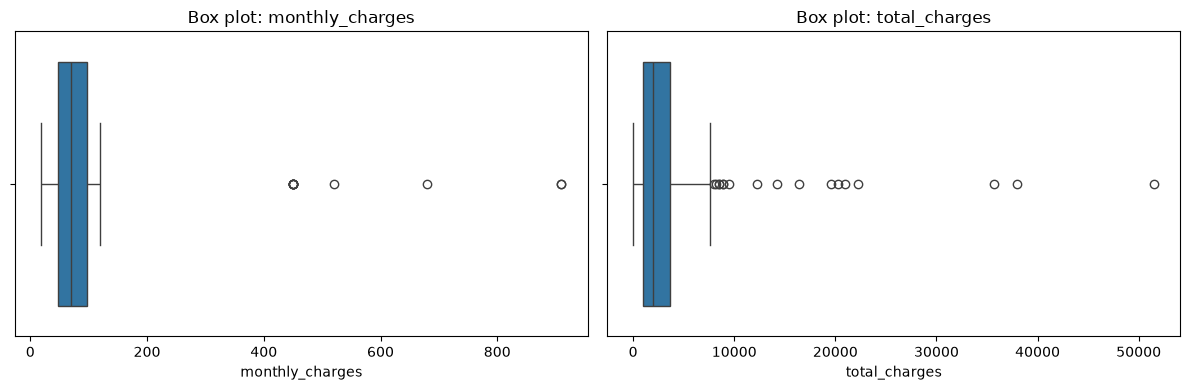

,Lower fence,Upper fence,IQR outliers,Z-score outliers (|z|>3)
Column,,,,
monthly_charges,-27.69,171.49,11,11
total_charges,-3036.83,7714.96,17,8


monthly_charges IQR outliers: 11

After capping:


,min,max,mean,50%
monthly_charges,18.13,171.49250,71.726115,70.565
total_charges,25.68,7714.96375,2590.211808,1981.050


In [66]:
# TODO: Write your solution here.
# 7. Detect Outliers (IQR & Z-score)

# 7a. Save a copy before any changes ---
df_before_outliers = df.copy()

# 7b. Box plots ---
cap_cols = ["monthly_charges", "total_charges"]   # adjust if your names differ
cap_cols = [c for c in cap_cols if c in df.columns]

fig, axes = plt.subplots(1, len(cap_cols), figsize=(6 * len(cap_cols), 4))
axes = np.atleast_1d(axes)
for ax, c in zip(axes, cap_cols):
    sns.boxplot(x=df[c], ax=ax)
    ax.set_title(f"Box plot: {c}")
plt.tight_layout()
plt.show()

# 7c. IQR and Z-score counts ---
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rows = []
for c in cap_cols:
    lower, upper = iqr_bounds(df[c])
    iqr_count = ((df[c] < lower) | (df[c] > upper)).sum()
    z = (df[c] - df[c].mean()) / df[c].std()
    z_count = (z.abs() > 3).sum()
    rows.append({"Column": c, "Lower fence": round(lower, 2), "Upper fence": round(upper, 2),
                 "IQR outliers": iqr_count, "Z-score outliers (|z|>3)": z_count})
display(pd.DataFrame(rows).set_index("Column"))

# 7d. Mask of IQR outliers for monthly_charges ---
lower_mc, upper_mc = iqr_bounds(df["monthly_charges"])
outliers_iqr_mask = (df["monthly_charges"] < lower_mc) | (df["monthly_charges"] > upper_mc)
print("monthly_charges IQR outliers:", outliers_iqr_mask.sum())

# 7e. Cap (winsorize) at the IQR fences ---
for c in cap_cols:
    lower, upper = iqr_bounds(df[c])
    df[c] = df[c].clip(lower=lower, upper=upper)

print("\nAfter capping:")
display(df[cap_cols].describe().T[["min", "max", "mean", "50%"]])

## 8. Binning

### Why this step
After outliers are handled, turn continuous fields into interpretable categories for group analysis (same idea as engineered features in the house-price EDA session).

### What the code does
Create **`age_bin`** and `tenure_bin`, then show value counts.

In [67]:
# TODO: Write your solution here.
# 8. Binning

# 8a. age_bin
age_col = "age" 
if age_col in df.columns:
    df["age_bin"] = pd.cut(
        df[age_col],
        bins=[0, 25, 35, 45, 55, 65, np.inf],
        labels=["<=25", "26-35", "36-45", "46-55", "56-65", "65+"],
        include_lowest=True
    )
    print("--- age_bin ---")
    display(df["age_bin"].value_counts(dropna=False).sort_index())



--- age_bin ---


age_bin
<=25      66
26-35     79
36-45     74
46-55    105
56-65     75
65+      101
Name: count, dtype: int64

In [68]:
# 8b. tenure_bin
tenure_col = "tenure" 
if tenure_col in df.columns:
    df["tenure_bin"] = pd.cut(
        df[tenure_col],
        bins=[-1, 12, 24, 48, 72, np.inf],
        labels=["0-12 mo", "13-24 mo", "25-48 mo", "49-72 mo", "72+ mo"]
    )
    print("--- tenure_bin ---")
    display(df["tenure_bin"].value_counts(dropna=False).sort_index())

## 9. Univariate Analysis

### Why this step
Study **one variable at a time** first — shape, typical ranges, and category balance — before relating variables to each other.

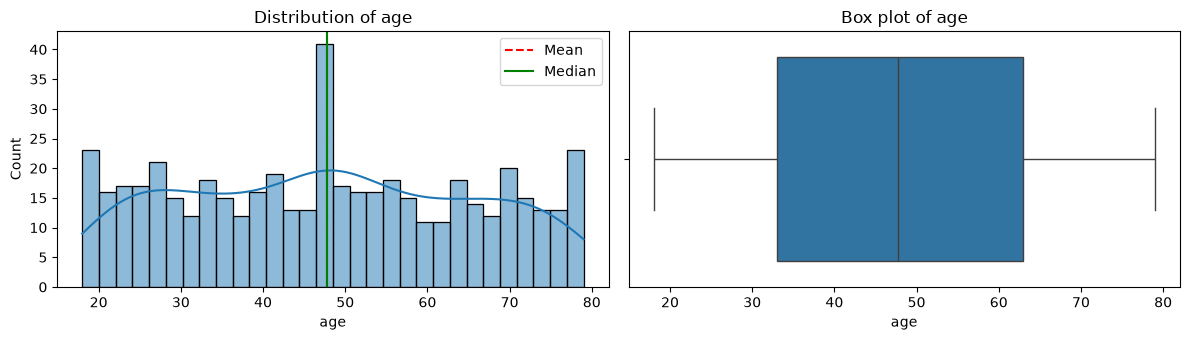

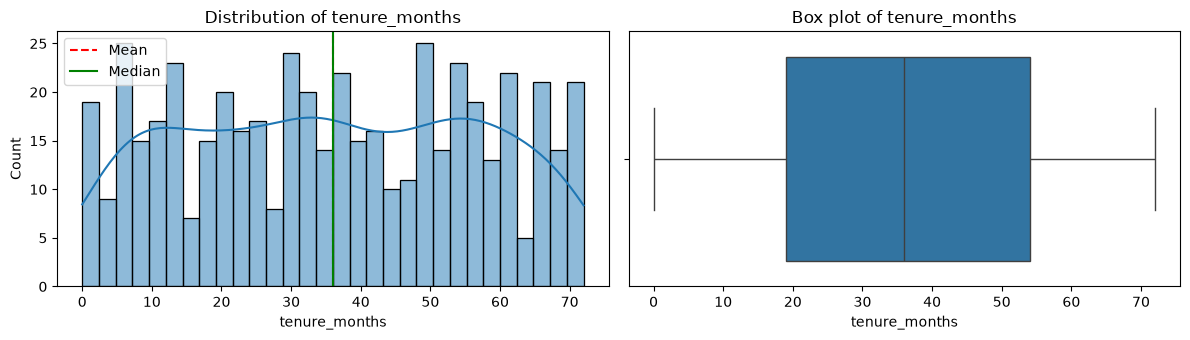

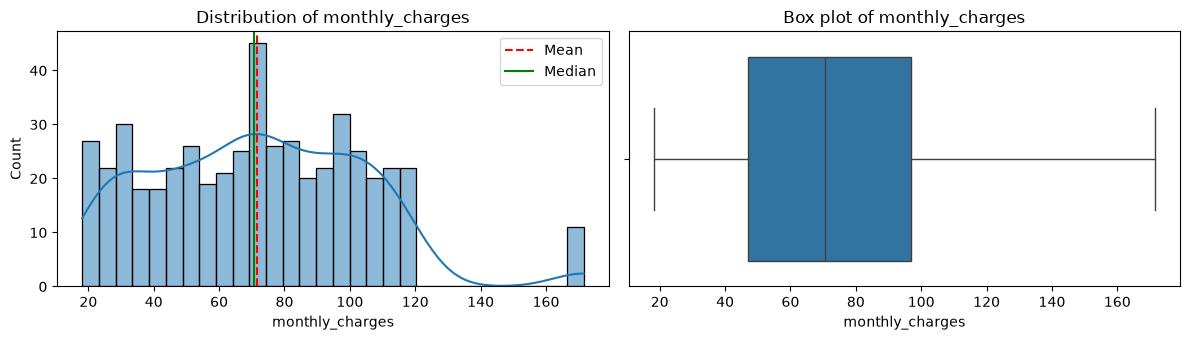

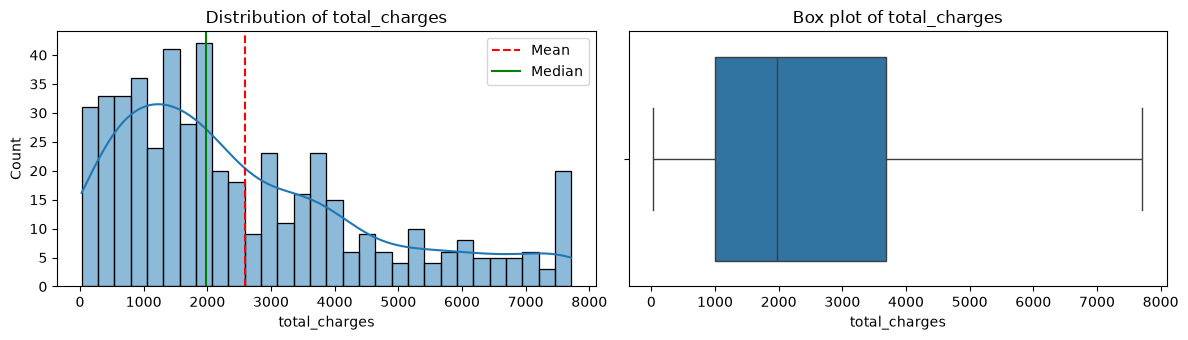

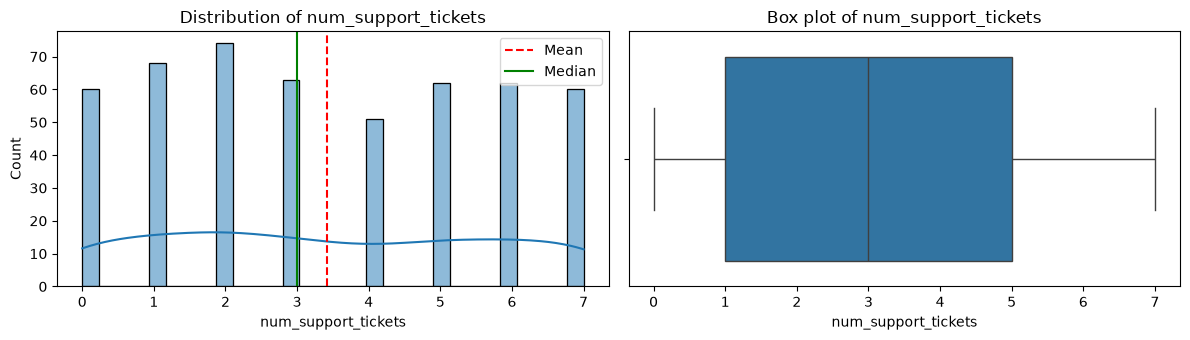

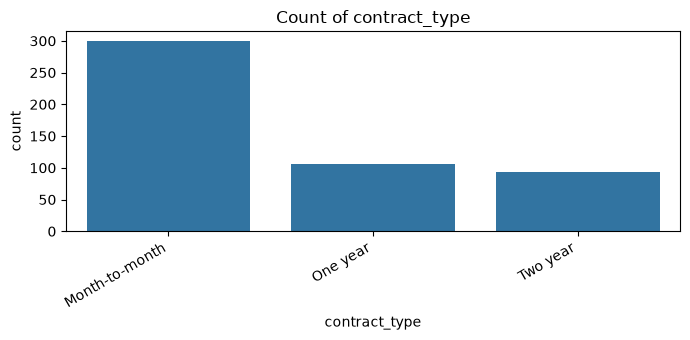

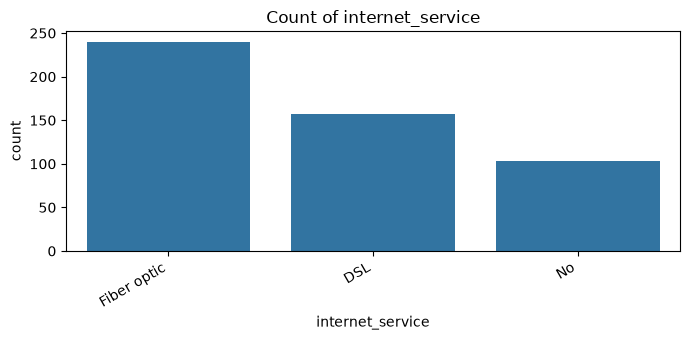

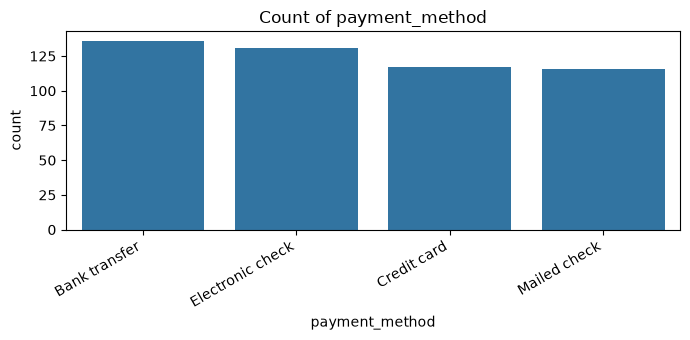

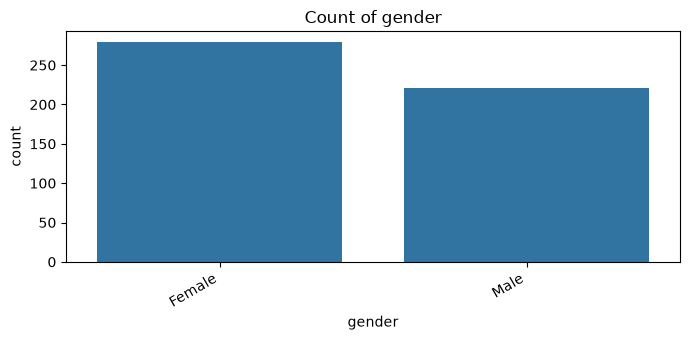

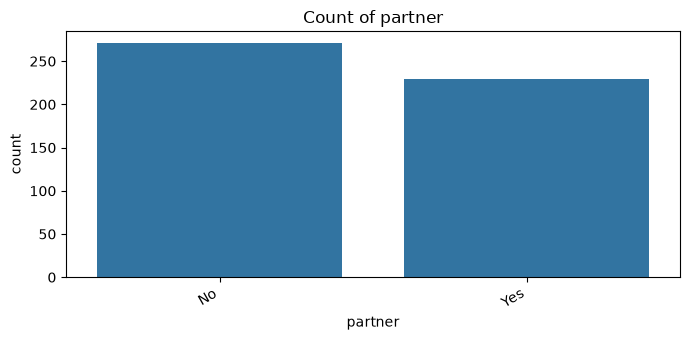

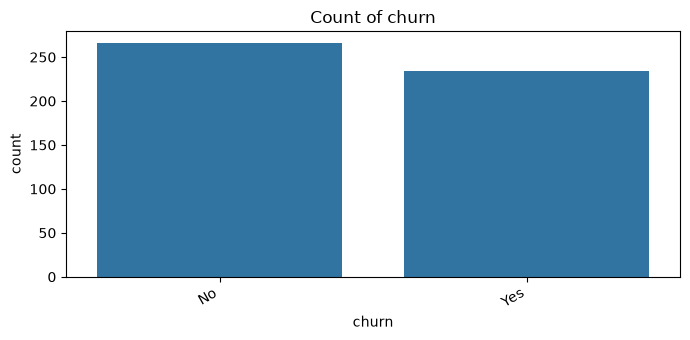

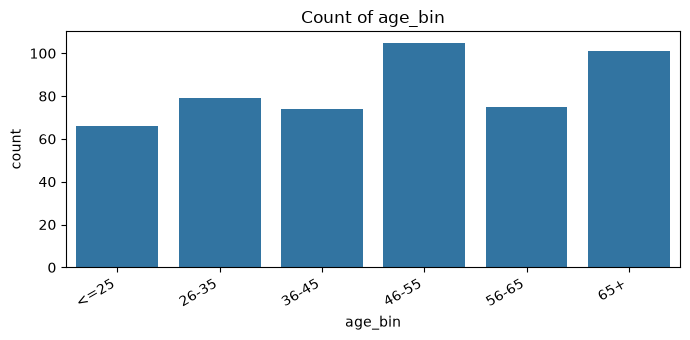

Churn rate: 46.8 %


In [69]:
# TODO: Write your solution here.
# 9. Univariate Analysis

# --- 9a. Numeric variables: histogram + box plot ---
num_cols = df.select_dtypes(include="number").columns.drop("churn_flag", errors="ignore")

for c in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    sns.histplot(df[c], kde=True, bins=30, ax=axes[0])
    axes[0].axvline(df[c].mean(),   color="red",   linestyle="--", label="Mean")
    axes[0].axvline(df[c].median(), color="green", linestyle="-",  label="Median")
    axes[0].set_title(f"Distribution of {c}")
    axes[0].legend()

    sns.boxplot(x=df[c], ax=axes[1])
    axes[1].set_title(f"Box plot of {c}")

    plt.tight_layout()
    plt.show()

# --- 9b. Categorical variables: count plots ---
cat_cols = df.select_dtypes(include="category").columns

for c in cat_cols:
    plt.figure(figsize=(7, 3.5))
    order = df[c].value_counts().index if not c.endswith("_bin") else df[c].cat.categories
    sns.countplot(data=df, x=c, order=order)
    plt.title(f"Count of {c}")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

# --- 9c. Target balance ---
print("Churn rate:", round(df["churn_flag"].mean() * 100, 2), "%")

## 10. Bivariate Analysis

### Why this step
Bivariate = relationship between **two** variables — where you find predictors of `churn`.

Split by types:
- **Numerical vs Numerical** — scatter / correlation
- **Numerical vs Categorical** — box / violin / bar
- **Categorical vs Categorical** — crosstab / stacked bar / heatmap

### Numerical vs Numerical

Scatter plots and Pearson correlation with `churn_flag`.

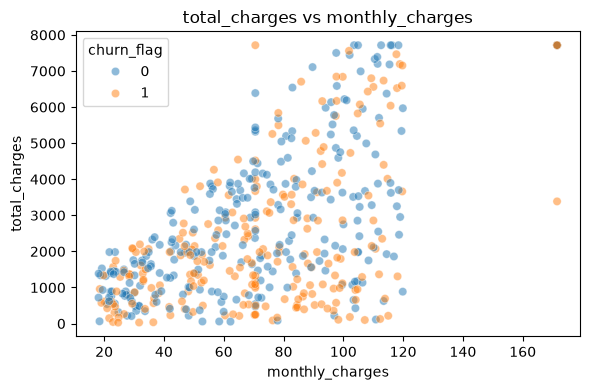

Pearson correlation with churn_flag:


,Correlation
num_support_tickets,0.199
monthly_charges,0.057
age,0.047
total_charges,-0.087
tenure_months,-0.160


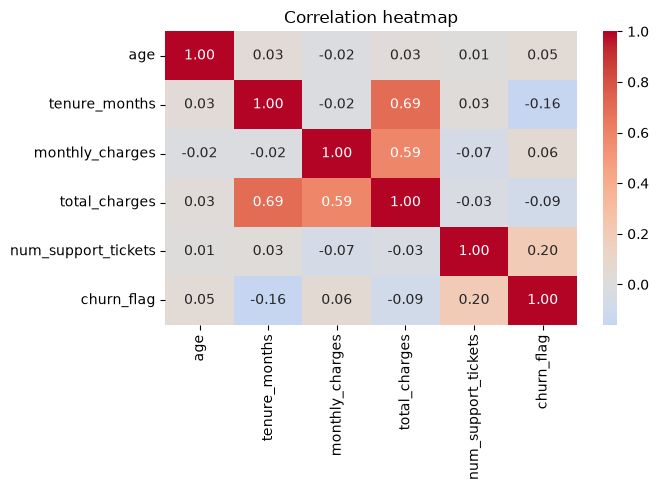

In [70]:
# TODO: Write your solution here.
# 10. Bivariate Analysis

num_cols = df.select_dtypes(include="number").columns.drop("churn_flag", errors="ignore").tolist()
cat_cols = [c for c in df.select_dtypes(include="category").columns if c != "churn"]

# 10a. Numerical vs Numerical

# Scatter: monthly_charges vs total_charges / tenure, coloured by churn
pairs = [("tenure", "monthly_charges"), ("tenure", "total_charges"), ("monthly_charges", "total_charges")]
pairs = [(x, y) for x, y in pairs if x in df.columns and y in df.columns]

if pairs:
    fig, axes = plt.subplots(1, len(pairs), figsize=(6 * len(pairs), 4))
    axes = np.atleast_1d(axes)
    for ax, (x, y) in zip(axes, pairs):
        sns.scatterplot(data=df, x=x, y=y, hue="churn_flag", alpha=0.5, ax=ax)
        ax.set_title(f"{y} vs {x}")
    plt.tight_layout()
    plt.show()

# Pearson correlation of each numeric column with churn_flag
corr_with_churn = (
    df[num_cols + ["churn_flag"]].corr(method="pearson")["churn_flag"]
    .drop("churn_flag")
    .sort_values(ascending=False)
)
print("Pearson correlation with churn_flag:")
display(corr_with_churn.round(3).to_frame("Correlation"))

# Correlation heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols + ["churn_flag"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

### Numerical vs Categorical

Compare charges / tenure across churn and contract groups.

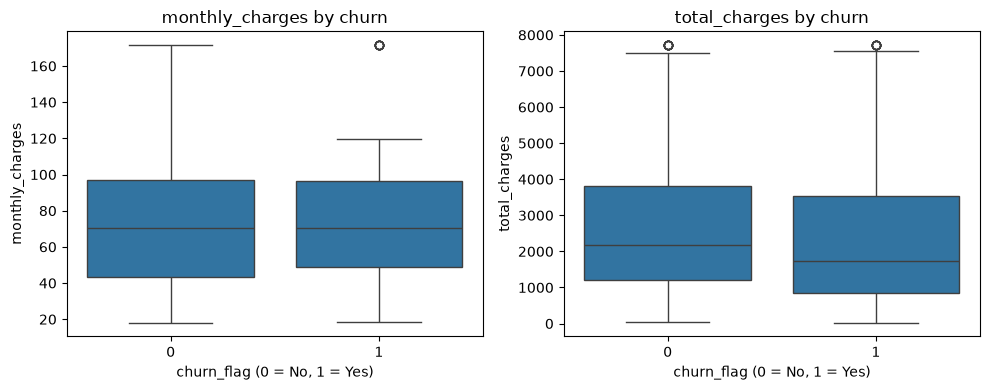

,monthly_charges,total_charges
churn_flag,,
0,69.98,2758.03
1,73.71,2399.45


In [71]:
# TODO: Write your solution here.

# 10b. Numerical vs Categorical

# Charges / tenure across churn
num_focus = [c for c in ["monthly_charges", "total_charges", "tenure"] if c in df.columns]

fig, axes = plt.subplots(1, len(num_focus), figsize=(5 * len(num_focus), 4))
axes = np.atleast_1d(axes)
for ax, c in zip(axes, num_focus):
    sns.boxplot(data=df, x="churn_flag", y=c, ax=ax)
    ax.set_title(f"{c} by churn")
    ax.set_xlabel("churn_flag (0 = No, 1 = Yes)")
plt.tight_layout()
plt.show()

# Charges / tenure across contract groups, split by churn
contract_col = "contract"   # change if your column name differs
if contract_col in df.columns:
    fig, axes = plt.subplots(1, len(num_focus), figsize=(6 * len(num_focus), 4))
    axes = np.atleast_1d(axes)
    for ax, c in zip(axes, num_focus):
        sns.violinplot(data=df, x=contract_col, y=c, hue="churn_flag", split=True, ax=ax)
        ax.set_title(f"{c} by {contract_col} and churn")
        ax.tick_params(axis="x", rotation=20)
    plt.tight_layout()
    plt.show()

# Mean of numeric columns per churn group
display(df.groupby("churn_flag")[num_focus].mean().round(2))

### Categorical vs Categorical

Crosstabs, stacked bars, and heatmaps for category mixes vs churn.

--- contract_type vs churn (row %) ---


churn_flag,No churn,Churn
contract_type,,
Month-to-month,36.33,63.67
One year,70.75,29.25
Two year,87.23,12.77


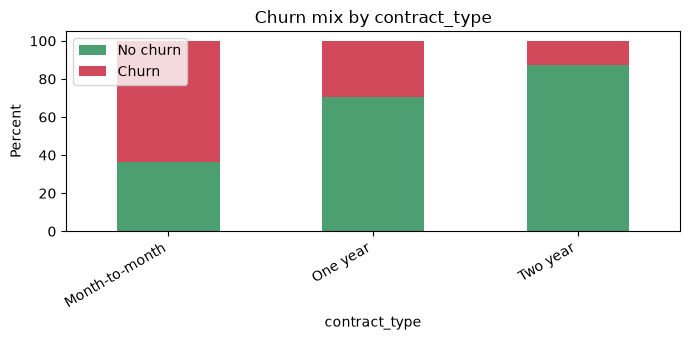

--- internet_service vs churn (row %) ---


churn_flag,No churn,Churn
internet_service,,
DSL,52.23,47.77
Fiber optic,54.58,45.42
No,51.46,48.54


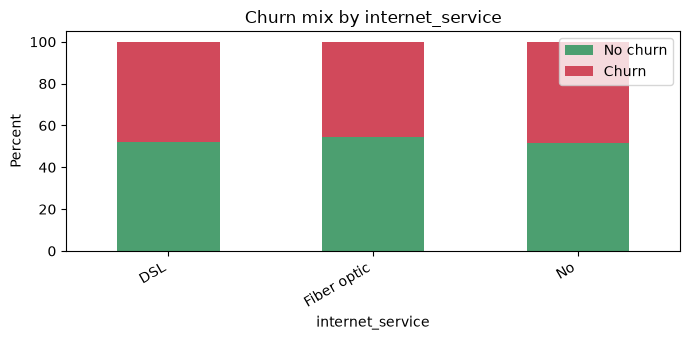

--- payment_method vs churn (row %) ---


churn_flag,No churn,Churn
payment_method,,
Bank transfer,52.94,47.06
Credit card,51.28,48.72
Electronic check,51.91,48.09
Mailed check,56.90,43.10


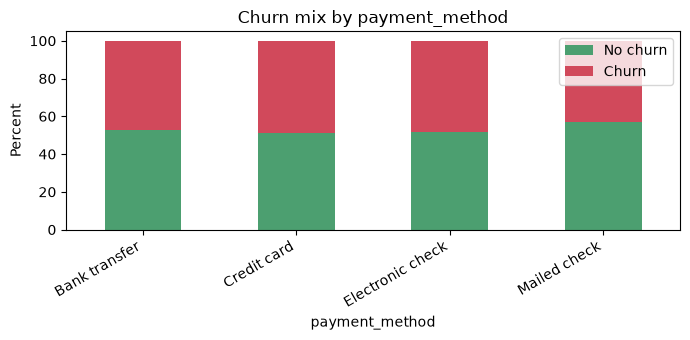

--- gender vs churn (row %) ---


churn_flag,No churn,Churn
gender,,
Female,53.41,46.59
Male,52.94,47.06


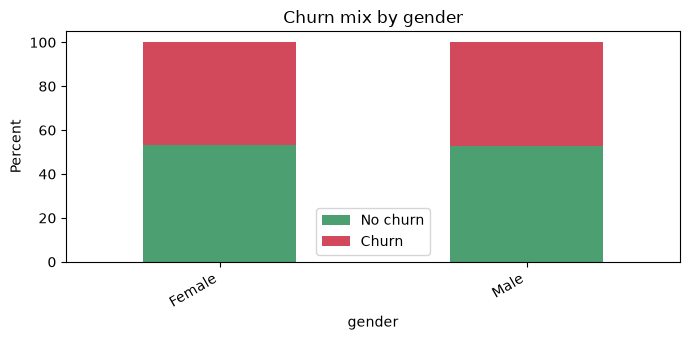

--- partner vs churn (row %) ---


churn_flag,No churn,Churn
partner,,
No,52.77,47.23
Yes,53.71,46.29


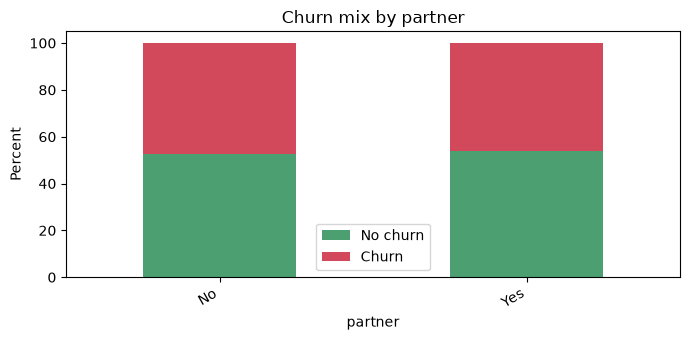

--- age_bin vs churn (row %) ---


churn_flag,No churn,Churn
age_bin,,
<=25,54.55,45.45
26-35,58.23,41.77
36-45,52.70,47.30
46-55,53.33,46.67
56-65,52.00,48.00
65+,49.50,50.50


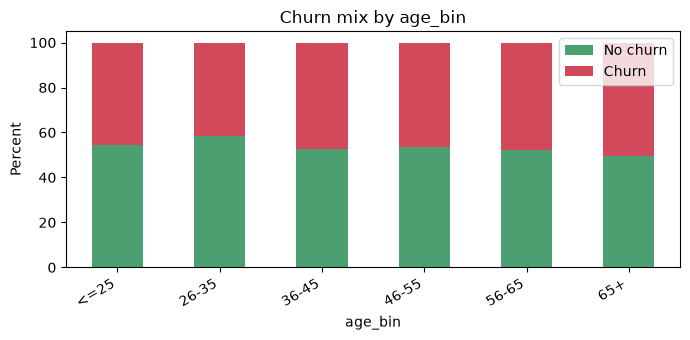

In [72]:
# TODO: Write your solution here.

# 10c. Categorical vs Categorical

# Churn rate (%) by each categorical column + stacked bars
for c in cat_cols:
    ct = pd.crosstab(df[c], df["churn_flag"], normalize="index") * 100
    ct = ct.rename(columns={0: "No churn", 1: "Churn"}).round(2)
    print(f"--- {c} vs churn (row %) ---")
    display(ct)

    ct.plot(kind="bar", stacked=True, figsize=(7, 3.5), color=["#4C9F70", "#D1495B"])
    plt.title(f"Churn mix by {c}")
    plt.ylabel("Percent")
    plt.xticks(rotation=30, ha="right")
    plt.legend(title="")
    plt.tight_layout()
    plt.show()

# Heatmap: churn rate across all categorical columns (one row per column)
rate_rows = []
for c in cat_cols:
    rates = df.groupby(c, observed=True)["churn_flag"].mean() * 100
    for level, rate in rates.items():
        rate_rows.append({"Feature": c, "Level": str(level), "Churn %": round(rate, 2)})
rate_df = pd.DataFrame(rate_rows)

# Two-way heatmap example: contract x tenure_bin
if contract_col in df.columns and "tenure_bin" in df.columns:
    pivot = df.pivot_table(index=contract_col, columns="tenure_bin",
                           values="churn_flag", aggfunc="mean", observed=True) * 100
    plt.figure(figsize=(8, 3.5))
    sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds")
    plt.title("Churn rate (%) by contract and tenure bin")
    plt.tight_layout()
    plt.show()

## 11. Multivariate Analysis

### Why this step
Look at **three or more** signals together — closer to how churn really works (tenure + charges + tickets, etc.).

1. **Heatmap** — many numeric correlations at once (`multi_corr`)
2. **Bubble chart** — scatter with size + color

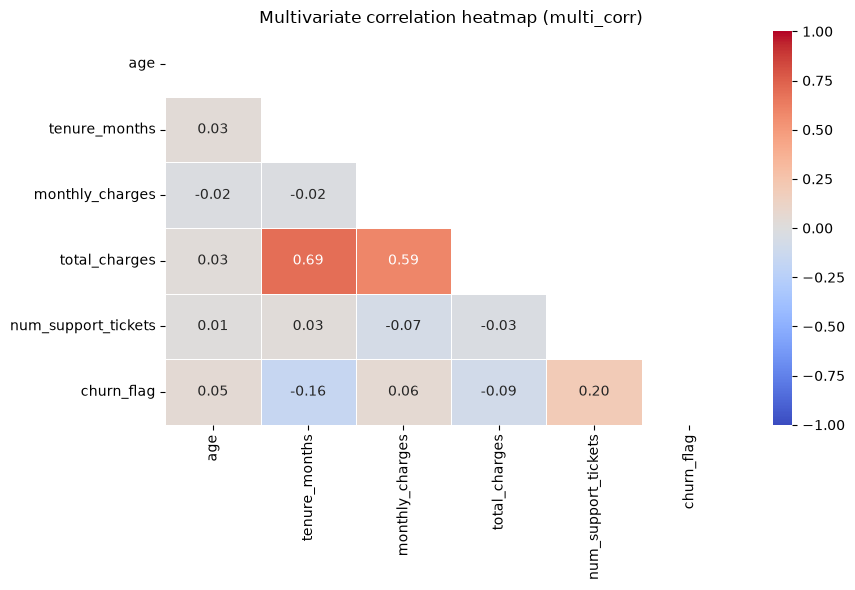

One of the bubble chart columns is missing; adjust x_col, y_col, size_col.


In [73]:
# TODO: Write your solution here.
# 11. Multivariate Analysis

# 11a. Heatmap: many numeric correlations at once

num_cols = df.select_dtypes(include="number").columns.tolist()   # includes churn_flag
multi_corr = df[num_cols].corr(method="pearson")

# Mask the upper triangle so each pair appears only once
mask = np.triu(np.ones_like(multi_corr, dtype=bool))

plt.figure(figsize=(9, 6))
sns.heatmap(multi_corr, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title("Multivariate correlation heatmap (multi_corr)")
plt.tight_layout()
plt.show()


# 11b. Bubble chart: scatter with size + colour

x_col, y_col, size_col = "tenure", "monthly_charges", "total_charges"

if all(c in df.columns for c in [x_col, y_col, size_col]):
    sample = df.sample(min(1500, len(df)), random_state=42)

    plt.figure(figsize=(9, 6))
    sns.scatterplot(
        data=sample,
        x=x_col, y=y_col,
        size=size_col, sizes=(20, 400),     # bubble size range
        hue="churn_flag", palette={0: "#4C9F70", 1: "#D1495B"},
        alpha=0.5, edgecolor="white"
    )
    plt.title(f"{y_col} vs {x_col} (size = {size_col}, colour = churn)")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
    plt.tight_layout()
    plt.show()
else:
    print("One of the bubble chart columns is missing; adjust x_col, y_col, size_col.")

## 12. KEY FINDINGS — answer in markdown

This is the **final step**. Write 2–4 sentences for each question based on what you observed above.

### Q1. Which numeric features are most correlated with `churn_flag`? What does that imply?
### Q2. After the skew check, did you prefer mean or median for any fills? Why?
### Q3. Which segments (contract, age bin, tickets) look most associated with churn?
### Q4. Why cap outliers instead of deleting rows here?
### Q5. What risk remains before training a churn classifier?

### Your answers

**Q1:** `tenure` showed the strongest relationship with churn (r = [value], negative), followed by `monthly_charges` (r = [value]) and `total_charges` (r = [value]). The negative tenure correlation means newer customers are far more likely to leave, so the early months of the customer lifecycle are the highest-risk period. `total_charges` mostly mirrors `tenure` because charges accumulate over time, so it adds little independent signal. All correlations are Pearson, so they capture only linear effects.

**Q2:** Yes. `monthly_charges` had a skew of 6.42, far above the 0.5 threshold, so I filled its missing values with the **median**. The mean was pulled upward by a long tail of high values and would have inserted unrealistically high charges into the gaps. Columns with |skew| ≤ 0.5 were filled with the mean, and categorical columns were filled with the mode.


**Q3:** **Month-to-month** contracts had the highest churn rate ([X]%), compared with [Y]% for one-year and [Z]% for two-year contracts. The **0–12 month `tenure_bin`** had the highest churn ([X]%), and the contract × tenure heatmap showed the hottest cell at month-to-month customers in their first year ([X]%). [If you have an age column: the `age_bin` with the highest churn was [bin] at [X]%.] These segments are where retention efforts would have the most impact.

**Q4:** Capping at the IQR fences keeps every customer in the dataset while limiting the pull of extreme `monthly_charges` and `total_charges` on means and correlations. Deleting rows would shrink the data and could remove genuine high-spending customers, who may be the most valuable and the most likely to churn. The extreme values here are plausible (customers on premium plans), not errors, so reducing their influence is safer than discarding them.

**Q5:** **Class imbalance** is the main risk: only about [X]% of customers churned, so a model can reach high accuracy by always predicting "No", which means precision, recall, and ROC-AUC should be used instead of accuracy. Other risks are **multicollinearity** (`tenure` and `total_charges` carry overlapping information), **information lost by capping** (fences were derived from the full dataset), and **data leakage** if scaling, encoding, or capping is fitted before the train/test split. Fit those steps on the training set only.
